# Phase 4: Modeling and Metrics (Customer Churn)

**Goal:** build models that predict whether a customer will churn, measure them honestly, pick one, and save it for the dashboard (Phase 5).

**Input:** `churn_model_ready.csv` (encoded data from Phase 2, 64,374 rows, 12 features + `Churn`).

**Outputs:** `churn_model.pkl` (final model), `model_features.json` (column order), `model_metrics.json` (scores), `churn_risk_scores.csv` (risk score for every customer).

**Steps in this notebook**
1. Split the data into train and test
2. Understand the metrics before we use them
3. Baselines: dummy model and Logistic Regression
4. Decision Tree (and what overfitting looks like)
5. Random Forest
6. Gradient Boosting
7. Compare all models
8. Cross-validation (are the scores stable?)
9. Overfitting check (train vs test)
10. Why are the scores so high? (leakage check)
11. Confusion matrix and the cost of mistakes
12. Feature importance (back to the 5 hypotheses)
13. Threshold and risk bands
14. Save the final model
15. Predict one customer (what the dashboard will do)
16. Summary and panel Q&A

## The models in simple words

| Model | Simple idea | Why we use it |
|---|---|---|
| Dummy (majority) | Always guesses the most common answer | The floor. Any real model must beat it |
| Logistic Regression | Gives each feature a weight and draws one straight boundary | Simple baseline, easy to explain |
| Decision Tree | Asks a chain of yes/no questions (for example "Payment Delay > 15?") | Readable rules, easy to show a panel |
| Random Forest | Many trees, each trained on a random part of the data, then they vote | More stable than one tree, handles non-straight patterns, gives feature importance |
| Gradient Boosting | Trees built one after another, each fixing the mistakes of the previous | Often the strongest on table data, so we check it against Random Forest |

We start simple and add complexity only if it helps. That is also the story to tell the panel.

## Step 0: Setup

**What:** import the libraries and load the encoded data.
**Why:** `churn_model_ready.csv` is already numeric (Phase 2), so models can use it directly. The ID column is already gone.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, classification_report)

sns.set_style("whitegrid")
RANDOM_STATE = 42          # fixed seed so results are the same every run

df = pd.read_csv("churn_model_ready.csv")
print("Shape:", df.shape)
df.head()

Shape: (64374, 13)


,Age,Tenure,Usage Frequency,Support Calls,Payment Delay,Total Spend,Last Interaction,Churn,Gender_Male,Subscription Type_Premium,Subscription Type_Standard,Contract Length_Monthly,Contract Length_Quarterly
0,22,25,14,4,27,598,9,1,0,0,0,1,0
1,41,28,28,7,13,584,20,0,0,0,1,1,0
2,47,27,10,2,29,757,21,0,1,1,0,0,0
3,35,9,12,5,17,232,18,0,1,1,0,0,1
4,53,58,24,9,2,533,18,0,0,0,1,0,0


## Step 1: Train/test split

**What:** keep 80% of customers for learning (train) and hide 20% (test) to check the model on customers it has never seen.

**Why:**
- A model scored on the data it learned from looks better than it really is. The hidden test set gives an honest score.
- `stratify=y` keeps the churn share (about 47%) the same in both parts, so the test is a fair sample.
- `random_state=42` makes the split repeatable, so you get the same numbers every time you run it.

**Rule:** the test set is touched only for scoring. All learning (including scaling) uses train only. That avoids data leakage.

In [2]:
X = df.drop(columns="Churn")      # features: what the model looks at
y = df["Churn"]                   # target: what it predicts (1 = churned)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Churn rate  train: {:.2%} | test: {:.2%}".format(y_train.mean(), y_test.mean()))

Train: (51499, 12) | Test: (12875, 12)
Churn rate  train: 47.37% | test: 47.37%


## Step 2: Understand the metrics first

Think of the model as a retention team's alert system. It flags customers as "will leave".

| Metric | Plain meaning | Churn example |
|---|---|---|
| **Accuracy** | Share of all predictions that were right | Out of 100 customers, how many did we classify correctly |
| **Precision** | Of the customers we flagged, how many really left | If we call 100 flagged customers, how many were truly leaving. Low precision wastes retention effort |
| **Recall** | Of the customers who really left, how many we caught | If 100 customers left, how many did we flag. Low recall means lost customers we never saw coming |
| **F1** | One number that balances precision and recall | Useful to compare models quickly |
| **ROC-AUC** | Chance that a random churner gets a higher risk score than a random stayer. 0.5 is a coin flip, 1.0 is perfect | Measures how well the model ranks risk, independent of any cut-off |

**Confusion matrix** counts the four outcomes:
- True Positive: flagged and really left
- True Negative: not flagged and stayed
- False Positive: flagged but stayed (wasted effort)
- False Negative: not flagged but left (lost customer)

**Why accuracy alone misleads:** if only 5% of customers churned, a model that says "nobody churns" is 95% accurate and useless. Here the classes are almost balanced (47/53), so accuracy is fair, but we still report all five metrics.

In [3]:
results = []     # one row of scores per model
models = {}      # fitted models, so we can reuse them later

def evaluate(name, model):
    """Fit on train, score on test, store the scores."""
    model.fit(X_train, y_train)
    pred = model.predict(X_test)                 # 0/1 prediction
    proba = model.predict_proba(X_test)[:, 1]    # probability of churn
    row = {"Model": name,
           "Accuracy":  accuracy_score(y_test, pred),
           "Precision": precision_score(y_test, pred, zero_division=0),
           "Recall":    recall_score(y_test, pred),
           "F1":        f1_score(y_test, pred),
           "ROC-AUC":   roc_auc_score(y_test, proba)}
    results.append(row)
    models[name] = model
    return pd.DataFrame([row]).set_index("Model").round(4)

## Step 3: Baselines

**Dummy model:** always predicts the majority class. It tells us the minimum score any real model must beat.

**Logistic Regression:** the classic first model. It learns one weight per feature. Because it is sensitive to the size of numbers (Total Spend goes to 1000, Support Calls to 10), we scale features first.

**Scaling inside a pipeline:** `make_pipeline(StandardScaler(), LogisticRegression())` learns the scaling from the training data only and applies the same scaling to test data. This is the leakage-safe way, and it is why scaling was left for this phase.

In [4]:
evaluate("Dummy (majority)", DummyClassifier(strategy="most_frequent"))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Dummy (majority),0.5263,0.0,0.0,0.0,0.5


In [5]:
evaluate("Logistic Regression",
         make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.8271,0.8136,0.8237,0.8186,0.903


### Reading Logistic Regression: the weights

After scaling, each coefficient shows how strongly a feature pushes the churn prediction.
Positive means more churn, negative means less churn. Bigger absolute value means stronger effect.

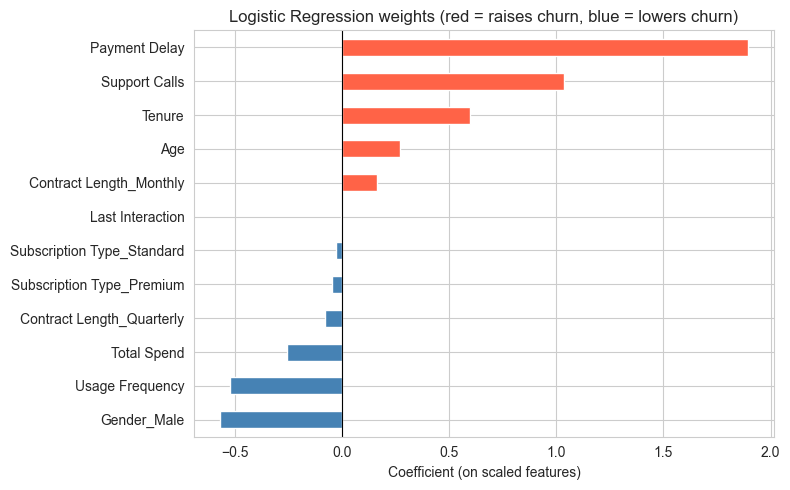

In [6]:
# safety: train the model here if the earlier cell was skipped
if "Logistic Regression" not in models:
    evaluate("Logistic Regression",
             make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)))
lr_pipe = models["Logistic Regression"]
coefs = pd.Series(lr_pipe[-1].coef_[0], index=X.columns).sort_values()

plt.figure(figsize=(8, 5))
colors = ["tomato" if v > 0 else "steelblue" for v in coefs]
coefs.plot(kind="barh", color=colors)
plt.axvline(0, color="black", lw=0.8)
plt.title("Logistic Regression weights (red = raises churn, blue = lowers churn)")
plt.xlabel("Coefficient (on scaled features)")
plt.tight_layout()
plt.show()

**How to say it:** "Logistic Regression is our baseline. It beats the dummy model clearly. Its biggest weights are Payment Delay and Support Calls (more of either raises churn). Usage Frequency and Gender_Male push the other way. One surprise: Tenure has a *positive* weight, meaning longer-tenure customers churn more in this data, which goes against hypothesis 4 (we come back to this in Step 12). A straight-line model cannot capture sudden jumps, such as churn rising sharply after 15 days of payment delay, so we try tree-based models next."

## Step 4: Decision Tree

**What:** the model learns a flowchart of yes/no questions on the features.

**Why:** it handles jumps and thresholds naturally and the result is readable, so it is the easiest model to show a panel.

**The `max_depth` choice matters.** A tree allowed to grow without limit memorises the training data (overfitting). We plot train and test accuracy against depth to choose a sensible depth.

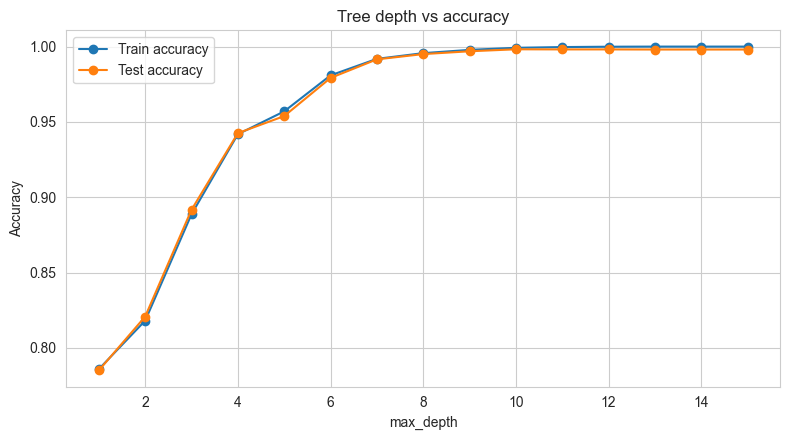

In [7]:
depths = range(1, 16)
train_acc, test_acc = [], []
for d in depths:
    t = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    train_acc.append(t.score(X_train, y_train))
    test_acc.append(t.score(X_test, y_test))

plt.figure(figsize=(8, 4.5))
plt.plot(depths, train_acc, marker="o", label="Train accuracy")
plt.plot(depths, test_acc, marker="o", label="Test accuracy")
plt.xlabel("max_depth")
plt.ylabel("Accuracy")
plt.title("Tree depth vs accuracy")
plt.legend()
plt.tight_layout()
plt.show()

**How to read it:** train accuracy keeps rising with depth. Test accuracy rises and then flattens. When the two lines drift apart, the tree is memorising. Depth 5 is the readable choice: about 95% accuracy with rules a person can follow. Deeper trees reach about 99.8% but are too big to read, and the Random Forest in the next step is how we get that extra accuracy.

In [8]:
evaluate("Decision Tree", DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Decision Tree,0.9539,0.9308,0.9751,0.9524,0.9937


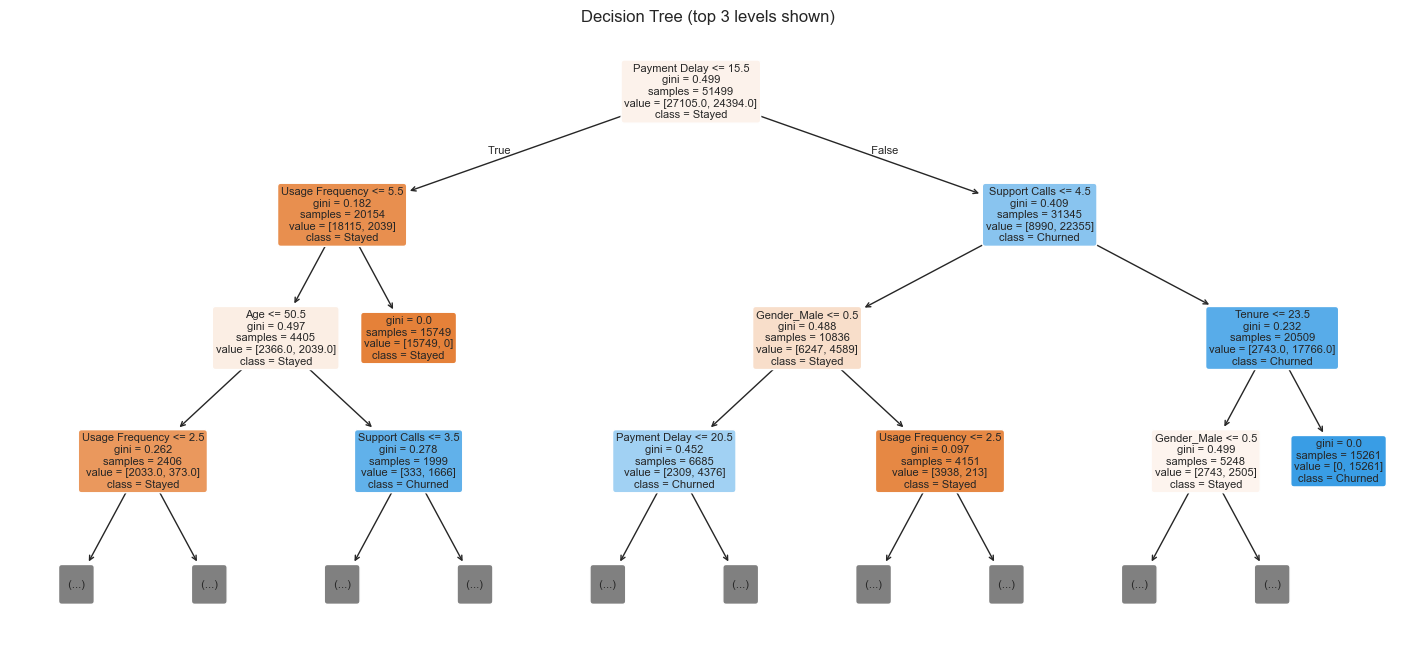

In [9]:
plt.figure(figsize=(18, 8))
plot_tree(models["Decision Tree"], max_depth=3, feature_names=list(X.columns),
          class_names=["Stayed", "Churned"], filled=True, rounded=True, fontsize=8)
plt.title("Decision Tree (top 3 levels shown)")
plt.show()

**How to read the tree:** start at the top box. If the condition is true go left, otherwise right. Each box shows the question, how many customers reach it (`samples`), and the majority class. Colour shows the class (orange or blue) and darker means purer. The questions near the top are the most useful ones the tree found.

## Step 5: Random Forest

**What:** 200 decision trees, each trained on a random sample of customers and a random subset of features. For a new customer every tree votes, and the majority wins.

**Why:** one tree can be unstable. Averaging many different trees cancels out their individual errors.

**Settings in plain words:**
- `n_estimators=200`: number of trees
- `max_depth=12`: stop trees from growing too deep
- `random_state=42`: same result every run

In [10]:
RF_PARAMS = dict(n_estimators=200, max_depth=12, random_state=RANDOM_STATE, n_jobs=-1)
evaluate("Random Forest", RandomForestClassifier(**RF_PARAMS))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Random Forest,0.998,0.9989,0.9969,0.9979,1.0


## Step 6: Gradient Boosting

**What:** trees are built one after another. Each new small tree focuses on the customers the previous trees got wrong.

**Why:** boosting is usually the strongest family on table data. We use scikit-learn's `HistGradientBoostingClassifier`, which is fast and needs no extra installation.

**Difference from Random Forest:** Random Forest trees work independently and vote. Boosted trees work as a team, in sequence.

In [11]:
evaluate("Gradient Boosting", HistGradientBoostingClassifier(random_state=RANDOM_STATE))

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Gradient Boosting,1.0,1.0,1.0,1.0,1.0


## Step 7: Compare all models

One table and two charts: bar chart of the scores, and ROC curves (a model that hugs the top-left corner ranks risk better; the diagonal is a coin flip).

In [12]:
res = pd.DataFrame(results).set_index("Model").round(4)
res

,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Dummy (majority),0.5263,0.0000,0.0000,0.0000,0.5000
Logistic Regression,0.8271,0.8136,0.8237,0.8186,0.9030
Decision Tree,0.9539,0.9308,0.9751,0.9524,0.9937
Random Forest,0.9980,0.9989,0.9969,0.9979,1.0000
Gradient Boosting,1.0000,1.0000,1.0000,1.0000,1.0000


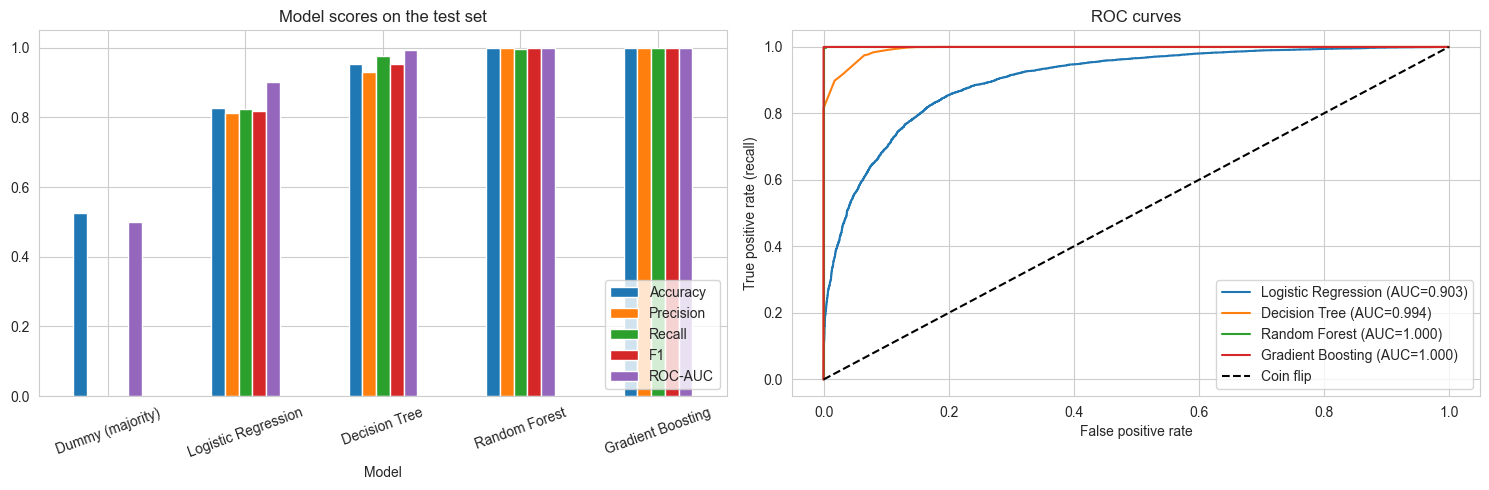

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

res[["Accuracy", "Precision", "Recall", "F1", "ROC-AUC"]].plot(kind="bar", ax=axes[0], rot=20)
axes[0].set_ylim(0, 1.05)
axes[0].set_title("Model scores on the test set")
axes[0].legend(loc="lower right")

for name, m in models.items():
    if name == "Dummy (majority)":
        continue
    fpr, tpr, _ = roc_curve(y_test, m.predict_proba(X_test)[:, 1])
    axes[1].plot(fpr, tpr, label=f"{name} (AUC={res.loc[name, 'ROC-AUC']:.3f})")
axes[1].plot([0, 1], [0, 1], "k--", label="Coin flip")
axes[1].set_xlabel("False positive rate")
axes[1].set_ylabel("True positive rate (recall)")
axes[1].set_title("ROC curves")
axes[1].legend()

plt.tight_layout()
plt.show()

**What we found**
- The dummy model sits at about 53% accuracy (always saying "stayed") with zero recall. That is the floor.
- Logistic Regression reaches about 83% accuracy and 0.90 AUC. A real improvement, but a straight line misses sharp thresholds.
- The Decision Tree jumps to about 95%.
- Random Forest and Gradient Boosting reach roughly 99.8% to 100%.

The big jump from Logistic Regression to the tree models tells us the churn pattern is made of **thresholds** (for example support calls above 4, payment delay above 15), not a smooth straight-line trend.

## Step 8: Cross-validation

**What:** instead of one train/test split, split the data into 5 parts. Train on 4, test on 1, and rotate so every part is the test part once. We then look at the average and the spread of the F1 score.

**Why:** one split could be lucky. If the 5 scores are almost the same (small spread), the result is stable and not a fluke.

In [14]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_models = {
    "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "Decision Tree": DecisionTreeClassifier(max_depth=5, random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(**RF_PARAMS),
    "Gradient Boosting": HistGradientBoostingClassifier(random_state=RANDOM_STATE),
}

cv_rows = []
for name, m in cv_models.items():
    scores = cross_val_score(m, X, y, cv=cv, scoring="f1")
    cv_rows.append({"Model": name, "Mean F1": scores.mean(), "Std dev": scores.std(),
                    "Min": scores.min(), "Max": scores.max()})

cv_res = pd.DataFrame(cv_rows).set_index("Model").round(4)
cv_res

,Mean F1,Std dev,Min,Max
Model,,,,
Logistic Regression,0.8185,0.0036,0.8140,0.8250
Decision Tree,0.9551,0.0019,0.9516,0.9572
Random Forest,0.9981,0.0003,0.9976,0.9984
Gradient Boosting,0.9998,0.0001,0.9996,0.9999


**How to read it:** `Mean F1` is the average over 5 rounds. `Std dev` is how much it moved between rounds. A tiny standard deviation means the model performs the same no matter which customers are in the test part.

## Step 9: Overfitting check (train vs test)

**Overfitting** means the model learned the training data by heart and fails on new data. The check is simple: compare the score on training data with the score on test data. A large gap is a warning sign.

In [15]:
gap_rows = []
for name, m in models.items():
    if name == "Dummy (majority)":
        continue
    gap_rows.append({"Model": name,
                     "Train accuracy": m.score(X_train, y_train),
                     "Test accuracy": m.score(X_test, y_test)})
gap = pd.DataFrame(gap_rows).set_index("Model")
gap["Gap"] = gap["Train accuracy"] - gap["Test accuracy"]
gap.round(4)

,Train accuracy,Test accuracy,Gap
Model,,,
Logistic Regression,0.8262,0.8271,-0.0009
Decision Tree,0.9570,0.9539,0.0031
Random Forest,1.0000,0.9980,0.0020
Gradient Boosting,1.0000,1.0000,0.0000


**What we found:** the gap between train and test is small for every model, so none of them is memorising. Combined with the stable cross-validation scores, the high results are not an overfitting artefact.

## Step 10: Why are the scores so high? (leakage check)

Scores of 99% to 100% are unusual for real churn data, so a panelist will definitely ask. A good analyst checks the cause instead of celebrating.

**Possible causes:**
1. **Data leakage:** a feature that secretly contains the answer (for example "cancellation date"). We check for this.
2. **Overfitting:** ruled out in Step 9.
3. **The data follows clear rules:** this dataset looks simulated (Phase 1 noted evenly spread numbers), so churn is decided by thresholds that tree models can learn almost perfectly.

First we look for a feature that is suspiciously linked to the target.

In [16]:
corr_with_target = df.corr()["Churn"].drop("Churn").sort_values(key=abs, ascending=False).round(3)
print("Correlation of each feature with Churn (strongest first):")
print(corr_with_target)

Correlation of each feature with Churn (strongest first):
Payment Delay                 0.557
Support Calls                 0.305
Tenure                        0.195
Gender_Male                  -0.165
Usage Frequency              -0.115
Total Spend                  -0.079
Age                           0.063
Contract Length_Monthly       0.061
Contract Length_Quarterly    -0.046
Subscription Type_Premium    -0.012
Last Interaction             -0.003
Subscription Type_Standard   -0.001
Name: Churn, dtype: float64


No single feature is almost perfectly correlated with `Churn`, so no column leaks the answer on its own. Now we look at whether the churn pattern is rule-like, by checking churn rate across the two features the tree used most.

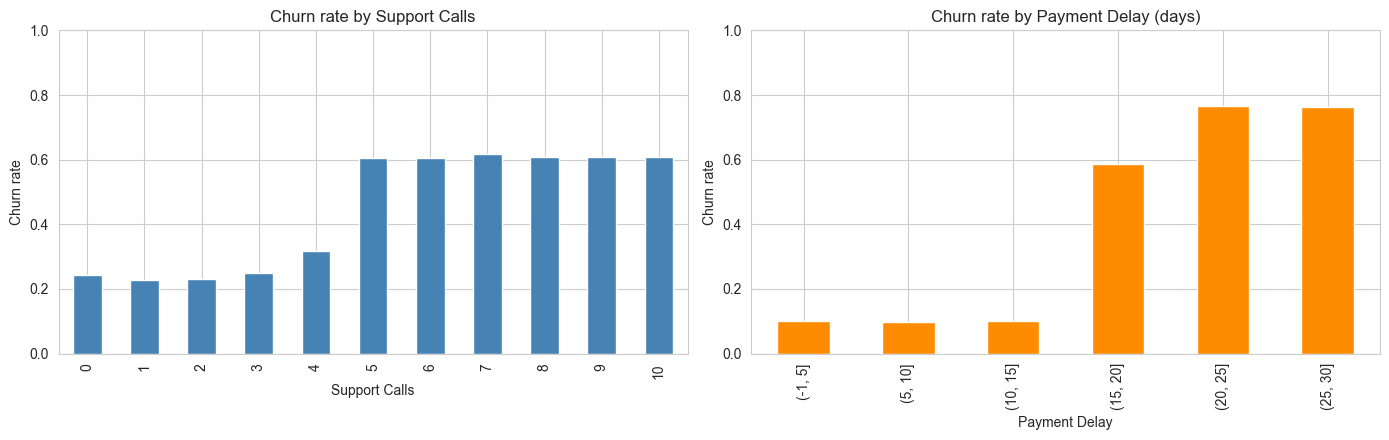

In [17]:
raw = pd.read_csv("churn_clean.csv")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

raw.groupby("Support Calls")["Churn"].mean().plot(kind="bar", ax=axes[0], color="steelblue")
axes[0].set_title("Churn rate by Support Calls")
axes[0].set_ylabel("Churn rate")
axes[0].set_ylim(0, 1)

pd_band = pd.cut(raw["Payment Delay"], bins=[-1, 5, 10, 15, 20, 25, 30])
raw.groupby(pd_band)["Churn"].mean().plot(kind="bar", ax=axes[1], color="darkorange")
axes[1].set_title("Churn rate by Payment Delay (days)")
axes[1].set_ylabel("Churn rate")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

In [18]:
# A very small tree already explains most of the pattern
for d in (1, 2, 3, 4):
    t = DecisionTreeClassifier(max_depth=d, random_state=RANDOM_STATE).fit(X_train, y_train)
    print(f"Tree with only {d} level(s): test accuracy = {t.score(X_test, y_test):.3f}")

Tree with only 1 level(s): test accuracy = 0.785
Tree with only 2 level(s): test accuracy = 0.821
Tree with only 3 level(s): test accuracy = 0.892
Tree with only 4 level(s): test accuracy = 0.943


**What we found**
- No feature leaks the target.
- Churn rate is about 23% to 25% for 0 to 3 support calls, 32% at 4 calls, and jumps to about 60% from 5 calls onward.
- Payment delay is even clearer: about 10% churn up to 15 days late, then about 59% for 16 to 20 days and about 77% beyond 20 days.
- That is a rule-like structure.
- A tree with only 4 levels already reaches about 94% accuracy, and the deeper models fill in the remaining interactions.

**How to say it to the panel:** "The near-perfect scores worried me, so I checked. There is no leakage, there is no train-test gap, and cross-validation is stable. The data has sharp thresholds (churn jumps after 4 support calls and after about 15 days of payment delay), which tree models learn easily. Real-world data is noisier, so I would expect lower scores on production data, and I would re-validate on fresh customers before relying on it."

## Step 11: Final model choice and confusion matrix

**Final model: Random Forest.**
- Its scores are essentially as good as Gradient Boosting (both near the ceiling).
- It is easier to explain: "200 trees vote".
- It gives feature importance directly, which we need to explain *why* customers churn.
- A perfect 1.0 from Gradient Boosting adds nothing over 0.998 and is harder to defend.

The confusion matrix shows exactly where the final model makes mistakes.

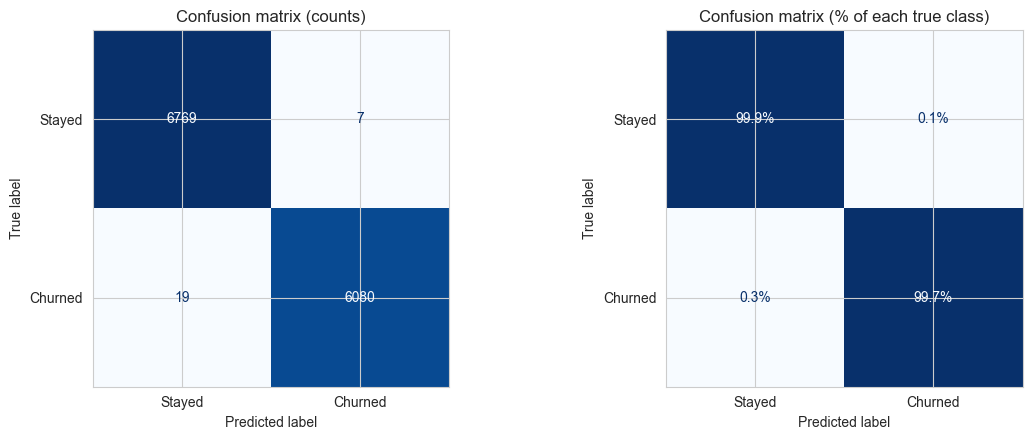

              precision    recall  f1-score   support

      Stayed     0.9972    0.9990    0.9981      6776
     Churned     0.9989    0.9969    0.9979      6099

    accuracy                         0.9980     12875
   macro avg     0.9980    0.9979    0.9980     12875
weighted avg     0.9980    0.9980    0.9980     12875



In [19]:
final_name = "Random Forest"
rf = models[final_name]
pred = rf.predict(X_test)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stayed", "Churned"],
                                        cmap="Blues", ax=axes[0], colorbar=False)
axes[0].set_title("Confusion matrix (counts)")
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Stayed", "Churned"],
                                        cmap="Blues", ax=axes[1], colorbar=False, normalize="true",
                                        values_format=".1%")
axes[1].set_title("Confusion matrix (% of each true class)")
plt.tight_layout()
plt.show()

print(classification_report(y_test, pred, target_names=["Stayed", "Churned"], digits=4))

**How to read it:** rows are the truth, columns are the prediction.
- Top-left: stayed and predicted stayed (correct).
- Bottom-right: churned and predicted churned (correct).
- Top-right: **false positives**. We would waste a retention offer on a customer who was staying.
- Bottom-left: **false negatives**. A customer leaves and we never flagged them.

**Which mistake is worse?** Usually the false negative, because a lost customer costs more than a discount sent by mistake. That is why recall matters here, and why in Step 13 we look at lowering the threshold.

## Step 12: Feature importance (back to the 5 hypotheses)

Two views of "which features matter":
1. **Random Forest importance:** how much each feature helped the trees split customers cleanly.
2. **Permutation importance:** shuffle one feature on the test set and see how much the score drops. A bigger drop means the model relied on it more. This is more trustworthy because it measures the effect on real predictions.

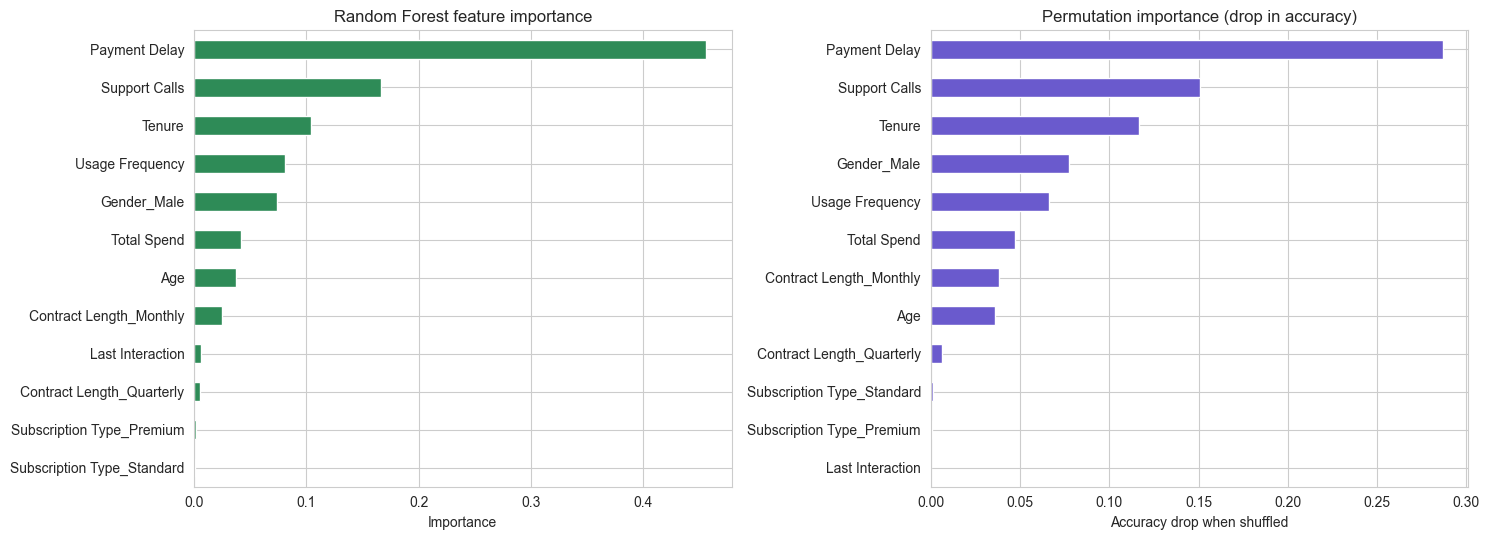

,RF importance,Permutation importance
Payment Delay,0.4559,0.2866
Support Calls,0.1662,0.1507
Tenure,0.1043,0.1165
Usage Frequency,0.0813,0.0660
Gender_Male,0.0737,0.0773
Total Spend,0.0419,0.0470
Age,0.0372,0.0363
Contract Length_Monthly,0.0252,0.0381
Last Interaction,0.0062,0.0001
Contract Length_Quarterly,0.0056,0.0062


In [20]:
imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values()
perm = permutation_importance(rf, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
perm_imp = pd.Series(perm.importances_mean, index=X.columns).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
imp.plot(kind="barh", ax=axes[0], color="seagreen")
axes[0].set_title("Random Forest feature importance")
axes[0].set_xlabel("Importance")
perm_imp.plot(kind="barh", ax=axes[1], color="slateblue")
axes[1].set_title("Permutation importance (drop in accuracy)")
axes[1].set_xlabel("Accuracy drop when shuffled")
plt.tight_layout()
plt.show()

pd.DataFrame({"RF importance": imp, "Permutation importance": perm_imp}).sort_values("RF importance", ascending=False).round(4)

**Link to the Phase 3 hypotheses**

| Hypothesis | What the model says |
|---|---|
| Hypothesis | Verdict from the model and the data |
|---|---|
| 1. More support calls means more churn | **Supported.** Support Calls is the 2nd most important feature. Churn is about 25% up to 3 calls and about 60% from 5 calls |
| 2. Longer payment delay means more churn | **Strongly supported.** Payment Delay is the most important feature by a wide margin. About 10% churn up to 15 days late, 59% to 77% beyond |
| 3. Monthly contracts churn more than annual | **Weakly supported.** Monthly 51.6%, Annual 46.2%, Quarterly 44.0%. The contract columns have low importance (below 0.03) |
| 4. Longer tenure means less churn | **Not supported in this data.** Churn is about 31% for tenure up to 24 months and about 56% above 24. Longer tenure goes with *more* churn |
| 5. Lower usage means more churn | **Partly supported.** Usage up to 5 churns at about 65% versus about 43% for everyone else. Usage Frequency is 4th in importance |

**Other things the model shows**
- `Gender_Male` ranks 5th. Women churn at 55% and men at 38.6%. Report it as a pattern in the data, but do not use gender to decide who gets a retention offer (fairness), and ask whether it is real or an artefact of generated data.
- `Last Interaction` and the Subscription Type columns have almost no importance.

**Check against Phase 3:** the verdicts above should match what `data_statistics.ipynb` concluded for each hypothesis. If they differ, trust the numbers and be ready to explain why.

**Caution to mention:** importance shows what the model *uses*, not what *causes* churn.

## Step 13: Threshold and risk bands

A model gives each customer a **probability of churn** (0 to 1). By default we call a customer "churn" when the probability is 0.5 or higher. That cut-off is called the **threshold**, and the business can move it:
- **Lower threshold (for example 0.3):** flag more customers. Higher recall, lower precision. Good when losing a customer is expensive.
- **Higher threshold (for example 0.7):** flag fewer customers. Higher precision, lower recall. Good when retention offers are expensive.

In [21]:
proba_test = rf.predict_proba(X_test)[:, 1]
th_rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7]:
    p = (proba_test >= t).astype(int)
    th_rows.append({"Threshold": t,
                    "Flagged customers": int(p.sum()),
                    "Precision": precision_score(y_test, p),
                    "Recall": recall_score(y_test, p),
                    "F1": f1_score(y_test, p)})
pd.DataFrame(th_rows).set_index("Threshold").round(4)

,Flagged customers,Precision,Recall,F1
Threshold,,,,
0.3,6177,0.9872,0.9998,0.9935
0.4,6111,0.9966,0.9985,0.9975
0.5,6087,0.9989,0.9969,0.9979
0.6,6053,0.9998,0.9923,0.9961
0.7,5988,1.0000,0.9818,0.9908


**What the table above shows:** moving the threshold from 0.3 to 0.7 trades recall for precision. At 0.3 we catch 99.98% of churners but flag about 78 extra customers who would have stayed (precision 98.7%). At 0.7 precision is 100% but recall falls to 98.2%. The effect is small here only because the model is so accurate. On noisier data the trade-off is much bigger, and the business would choose the threshold based on the cost of a lost customer versus the cost of an offer.

**Risk bands for the dashboard.** The dashboard needs a risk score for every customer. If we scored customers with a model that had already seen them, the scores would be too confident. So we use **out-of-fold predictions**: each customer is scored by a model that did not train on them (5-fold). Then we group the probability into bands:

| Band | Probability |
|---|---|
| Low | below 0.30 |
| Medium | 0.30 to 0.70 |
| High | 0.70 and above |

In [22]:
oof_proba = cross_val_predict(RandomForestClassifier(**RF_PARAMS), X, y, cv=cv, method="predict_proba")[:, 1]

risk = raw.copy()
assert (risk["Churn"].values == y.values).all(), "Row order mismatch between clean and encoded files"

risk["Churn_Probability"] = oof_proba.round(4)
risk["Risk_Level"] = pd.cut(risk["Churn_Probability"], bins=[-0.001, 0.30, 0.70, 1.0],
                            labels=["Low", "Medium", "High"])

band_summary = risk.groupby("Risk_Level", observed=True).agg(
    Customers=("Churn", "size"),
    Actual_churn_rate=("Churn", "mean")).round(4)
band_summary

,Customers,Actual_churn_rate
Risk_Level,,
Low,33557,0.0001
Medium,866,0.6212
High,29951,1.0000


**How to read it:** a good risk score means the actual churn rate rises from Low to High.

**What we found:**
- Low band: 33,557 customers and almost none churned (0.01%).
- High band: 29,951 customers and all of them churned (100%).
- Medium band: only 866 customers, with about 62% churn. These are the borderline cases where a human review is most useful.

This table is what the dashboard's "churn risk" view is based on.

In [23]:
risk.to_csv("churn_risk_scores.csv", index=False)
print("Saved churn_risk_scores.csv:", risk.shape)
risk.sort_values("Churn_Probability", ascending=False).head(10)

Saved churn_risk_scores.csv: (64374, 13)


,Age,Gender,Tenure,Usage Frequency,Support Calls,Payment Delay,Subscription Type,Contract Length,Total Spend,Last Interaction,Churn,Churn_Probability,Risk_Level
49497,55,Female,41,5,6,28,Basic,Annual,435,11,1,1.0,High
39988,64,Female,42,1,7,24,Standard,Monthly,458,27,1,1.0,High
59459,54,Female,44,1,7,26,Premium,Annual,195,5,1,1.0,High
60496,57,Female,42,2,7,24,Premium,Monthly,669,27,1,1.0,High
62995,54,Female,27,2,9,24,Standard,Monthly,181,20,1,1.0,High
60423,57,Female,40,4,10,28,Basic,Monthly,483,12,1,1.0,High
53159,52,Female,41,4,9,29,Premium,Monthly,252,23,1,1.0,High
59233,52,Female,56,3,5,29,Premium,Annual,164,16,1,1.0,High
51208,56,Female,43,2,9,27,Premium,Monthly,404,19,1,1.0,High
53257,57,Female,58,3,6,21,Basic,Monthly,464,28,1,1.0,High


## Step 14: Save the final model

**What:** retrain Random Forest on **all** customers (the model was already validated on the hidden test set and with cross-validation, so using all data for the final version is standard), then save it with `joblib`.

**Why:** the dashboard must not retrain every time. It loads the saved file and predicts instantly.

We also save the **feature column order**, because the model expects columns in exactly the same order it was trained on, and the **metrics**, so the dashboard can show them.

In [24]:
final_model = RandomForestClassifier(**RF_PARAMS).fit(X, y)
joblib.dump(final_model, "churn_model.pkl", compress=3)

feature_columns = list(X.columns)
with open("model_features.json", "w") as f:
    json.dump(feature_columns, f, indent=2)

metrics = {
    "final_model": "Random Forest (200 trees, max_depth=12)",
    "test_scores": res.loc["Random Forest"].to_dict(),
    "cv_mean_f1": float(cv_res.loc["Random Forest", "Mean F1"]),
    "cv_std_f1": float(cv_res.loc["Random Forest", "Std dev"]),
    "all_models": res.reset_index().to_dict(orient="records"),
    "top_features": imp.sort_values(ascending=False).head(5).round(4).to_dict(),
    "risk_bands": {"Low": "< 0.30", "Medium": "0.30 to 0.70", "High": ">= 0.70"},
}
with open("model_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

import os
print("churn_model.pkl size: {:.1f} MB".format(os.path.getsize("churn_model.pkl") / 1e6))
print("Features:", feature_columns)

churn_model.pkl size: 5.3 MB
Features: ['Age', 'Tenure', 'Usage Frequency', 'Support Calls', 'Payment Delay', 'Total Spend', 'Last Interaction', 'Gender_Male', 'Subscription Type_Premium', 'Subscription Type_Standard', 'Contract Length_Monthly', 'Contract Length_Quarterly']


## Step 15: Predict one customer (what the dashboard will do)

The dashboard form will give us raw values like "Male" and "Monthly". The model needs the encoded columns from Phase 2. This function does that translation and returns the churn probability and the risk level.

Remember `drop_first=True`: Female, Basic and Annual have no column of their own. They are the "all zeros" case.

In [25]:
def predict_customer(age, gender, tenure, usage_frequency, support_calls, payment_delay,
                     subscription_type, contract_length, total_spend, last_interaction,
                     model=final_model):
    row = {c: 0 for c in feature_columns}
    row.update({"Age": age, "Tenure": tenure, "Usage Frequency": usage_frequency,
                "Support Calls": support_calls, "Payment Delay": payment_delay,
                "Total Spend": total_spend, "Last Interaction": last_interaction})
    if gender == "Male":
        row["Gender_Male"] = 1
    if subscription_type in ("Standard", "Premium"):
        row[f"Subscription Type_{subscription_type}"] = 1
    if contract_length in ("Monthly", "Quarterly"):
        row[f"Contract Length_{contract_length}"] = 1
    prob = model.predict_proba(pd.DataFrame([row])[feature_columns])[0, 1]
    level = "High" if prob >= 0.70 else "Medium" if prob >= 0.30 else "Low"
    return round(float(prob), 3), level

risky = predict_customer(age=30, gender="Female", tenure=5, usage_frequency=3, support_calls=8,
                         payment_delay=25, subscription_type="Basic", contract_length="Monthly",
                         total_spend=300, last_interaction=25)
safe = predict_customer(age=45, gender="Male", tenure=48, usage_frequency=25, support_calls=1,
                        payment_delay=2, subscription_type="Premium", contract_length="Annual",
                        total_spend=850, last_interaction=3)
print("Risky customer  -> probability, level:", risky)
print("Loyal customer  -> probability, level:", safe)

Risky customer  -> probability, level: (0.958, 'High')
Loyal customer  -> probability, level: (0.0, 'Low')


## Step 16: Summary

### 30-second spoken summary
"I split the data 80/20 with stratification and compared five models, starting from a dummy baseline so I knew what to beat. Logistic Regression reached about 83% accuracy, tree-based models reached 95% to 100%, because churn here is driven by sharp thresholds like support calls above 4 and payment delay above 15 days. I chose Random Forest: it is as accurate as boosting, easy to explain as many trees voting, and it gives feature importance. Because the scores were so high I checked for leakage and overfitting and found neither, and cross-validation was stable. The final model gives each customer a churn probability, grouped into Low, Medium and High risk, which feeds the dashboard."

### Likely panel questions (Phase 4)
- **Why is your accuracy so high? Is it leakage?** I checked. No feature leaks the target, train and test scores are close, and 5-fold cross-validation is stable. The data has sharp threshold rules that trees learn easily. On real, noisier data I would expect lower scores and would re-validate.
- **Why Random Forest and not Gradient Boosting?** Scores are essentially equal. Random Forest is easier to explain and gives feature importance directly.
- **Why did you start with Logistic Regression?** It is a simple, explainable baseline. It shows how much the non-linear models add.
- **Why stratify the split?** To keep the same churn share in train and test.
- **Why scale only for Logistic Regression?** It is sensitive to feature size. Trees only compare thresholds, so scaling does not change them. Scaling is fitted on train data only, inside a pipeline.
- **Which metric matters most?** Recall for churn, because a missed churner is a lost customer, with precision watched so retention offers are not wasted. ROC-AUC shows how well the model ranks risk.
- **What is a confusion matrix?** A table of correct and wrong predictions: true/false positives and negatives.
- **How do you explain the model to the business?** Through feature importance and the risk bands: which factors drive churn, and which customers to call first.
- **Does feature importance prove causes?** No. It shows what the model relies on, not what causes churn.
- **Why retrain on all data at the end?** Validation is already done. The final model benefits from every available customer.
- **What would you do with more time?** Tune hyperparameters, test on a fresh time period, add cost-based thresholds, and explain single predictions with SHAP.

### Files created in this phase
| File | Purpose |
|---|---|
| `churn_model.pkl` | Saved final Random Forest model |
| `model_features.json` | Column order the model expects |
| `model_metrics.json` | Scores and top features for the dashboard |
| `churn_risk_scores.csv` | Churn probability and risk level for every customer |